<a href="https://colab.research.google.com/github/juancamilomendez/telecom_analysis/blob/main/Version_Estudiante_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:

# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = users = pd.read_csv('/datasets/users_latam.csv') #completa el código
usage = usage = pd.read_csv('/datasets/usage.csv') #completa el código


In [ ]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
 # mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


In [ ]:

# cantidad de nulos para users
print("Cantidad de valores nulos en users:")
print(users.isna().sum())
print("\nProporción de valores nulos en users:")
print(users.isna().mean())


Cantidad de valores nulos en users:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos en users:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print("\nCantidad de valores nulos en usage:")
print(usage.isna().sum())
print("\nProporción de valores nulos en usage:")
print(usage.isna().mean())


Cantidad de valores nulos en usage:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos en usage:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

In [ ]:
# Diagnóstico:
# En users, city presenta aproximadamente 11.7% de valores nulos, por lo que se recomienda
# investigar su causa y mantenerlos temporalmente como nulos. churn_date presenta
# aproximadamente 88.4% de nulos, pero estos probablemente representan clientes que aún
# no han abandonado el servicio, por lo que no se deben eliminar.
#
# En usage, date presenta aproximadamente 0.1% de nulos, por lo que se puede investigar
# y tratar posteriormente. duration y length presentan una proporción elevada de nulos,
# por lo que primero se debe analizar su relación con type antes de imputar o eliminar
# valores, ya que los nulos podrían ser esperados según el tipo de uso.

In [ ]:
# explorar columnas numéricas de users
users[['user_id', 'age']].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...

In [ ]:
# explorar columnas numéricas de usage
usage[['id', 'user_id', 'duration', 'length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...

In [ ]:

# explorar columnas categóricas de users
columnas_user = ('city', 'plan')
print("Valores únicos de city:")
print(users['city'].unique())

print("\nValores únicos de plan:")
print(users['plan'].unique())



Valores únicos de city:
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']

Valores únicos de plan:
['Basico' 'Premium']


- La columna `city` ...
- La columna `plan` ...

In [ ]:
# explorar columna categórica de usage
usage['type'] # completa el código
print("\nValores únicos de type:")
print(usage['type'].unique())


Valores únicos de type:
['call' 'text']


- La columna `type` ...


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

*Valores inválidos o sentinels*  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- ¿Qué acción tomarías?
- Diagnóstico:

En users, la columna age presenta un valor mínimo de -999, que es un valor inválido y se considera un sentinel. Se recomienda reemplazarlo por NaN para tratarlo posteriormente como dato faltante.

La columna city contiene el valor '?' además de valores NaN. El '?' se considera un sentinel para representar una ciudad desconocida, por lo que se recomienda reemplazarlo por NaN.

Las columnas user_id, duration y length no presentan valores negativos ni otros valores claramente inválidos. Los valores 0 de duration y length se mantienen por ahora, ya que pueden tener significado dependiendo del tipo de registro.

La columna plan contiene únicamente 'Basico' y 'Premium', que coinciden con los planes disponibles en plans. La columna type contiene 'call' y 'text', categorías esperadas para los registros de uso. No requieren modificación.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce') # completa el código

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')# completa el código

In [ ]:
# Revisar los años presentes en `reg_date` de users
print("Años en reg_date:")
print(users['reg_date'].dt.year.value_counts().sort_index())


Años en reg_date:
2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

En reg_date, la mayoría de los registros corresponden a los años 2022, 2023 y 2024. Sin embargo, aparecen 40 registros con año 2026, que están fuera del período de análisis establecido hasta 2024. Se recomienda investigar estos registros y, si se confirma que corresponden a errores de captura, corregirlos o convertirlos en NaT antes del análisis.

In [ ]:
# Revisar los años presentes en `date` de usage
print("\nAños en date:")
print(usage['date'].dt.year.value_counts().sort_index())



Años en date:
2024.0    39950
Name: date, dtype: int64


En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

En la columna date, todos los registros con fecha válida corresponden al año 2024.

No se encontraron fechas de otros años ni fechas fuera del período de análisis.

Existen 50 registros sin fecha, que se mantienen como valores faltantes para tratarlos posteriormente según las reglas de limpieza.

Por lo tanto, el análisis de uso se basará en los registros correspondientes a 2024.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?
- Diagnóstico:

Las columnas reg_date y date fueron convertidas correctamente a formato datetime utilizando errors='coerce', lo que permite transformar fechas inválidas en NaT sin detener la ejecución del código.

Al revisar la distribución de años, se deben considerar válidos los registros correspondientes al período de análisis hasta 2024. Si no aparecen años posteriores a 2024 ni años claramente imposibles, no es necesario eliminar fechas.

En caso de encontrar fechas fuera de rango, se recomienda investigarlas y dependiendo de su causa, convertirlas en NaT o excluir esos registros del análisis.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)


# Verificar cambios
users['city'].isna().sum()



565

In [ ]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

# Verificar cambios
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
print("Nulos y no nulos de duration según type:")
print(pd.crosstab(usage['type'], usage['duration'].isna()))


Nulos y no nulos de duration según type:
duration  False  True 
type                  
call      17908      0
text         16  22076


In [ ]:
# Verificación MAR en usage (Missing At Random) para length
print("Nulos y no nulos de length según type:")
print(pd.crosstab(usage['type'], usage['length'].isna()))


Nulos y no nulos de length según type:
length  False  True 
type                
call       12  17896
text    22092      0


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Diagnóstico:
Los valores nulos de duration y length dependen claramente de la columna type.

En los registros de tipo call, duration está disponible y length es principalmente nulo. En los registros de tipo text, ocurre lo contrario: length está disponible
y duration es principalmente nulo.

Esto indica que los valores faltantes están relacionados con el tipo de registro
y no representan necesariamente errores de captura. Por esta razón, se consideran MAR dentro del contexto del ejercicio.

Se mantienen los valores nulos en duration y length, sin imputarlos ni eliminar los registros, ya que cada variable aplica principalmente a un tipo diferente de evento.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id")[["is_text", "is_call", "duration"]].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


In [ ]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()


,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.122250,5.524381,4.478120,23.317054
std,1154.844867,17.690408,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.120000
50%,11999.500000,47.000000,5.000000,4.000000,19.780000
75%,12999.250000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [ ]:
# Distribución porcentual del tipo de plan
user_profile["plan"].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

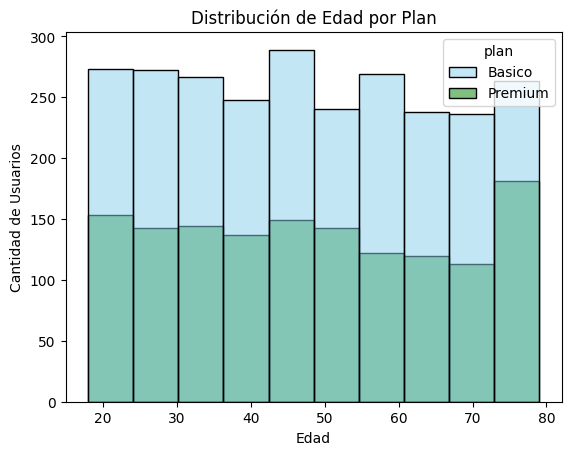

In [ ]:
# Histograma para visualizar la edad (age)
sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=10
)

plt.title('Distribución de Edad por Plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()


💡Insights:
- Distribución:

Observaciones clave del gráfico
- Segmento Senior (70 - 80 años):
Se observa la mayor proporción del plan Premium en el grupo de edad más avanzado (~80 años), donde la barra verde abarca casi el 70-80% del total de ese rango de edad.

- Adultos Jóvenes y Medios (18 - 60 años):
La adopción del plan Básico (área azul claro) es dominante y se mantiene constante (aproximadamente 50% - 60% de cada rango de edad).

- Distribución General de la Muestra:
El volumen total de usuarios por rango de edad es bastante uniforme a lo largo de todas las edades (alrededor de 250 usuarios por bloque decenal).

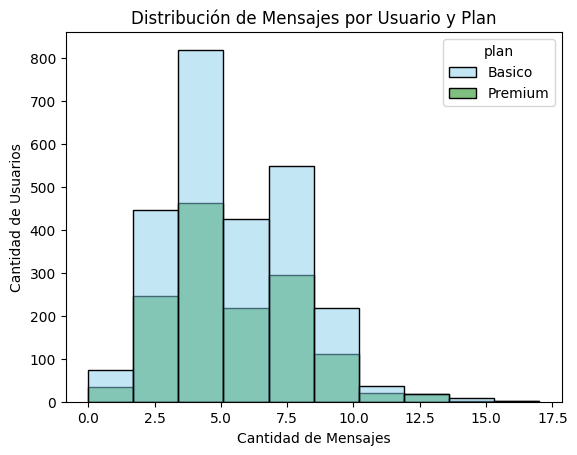

In [ ]:
# Histograma para visualizar la cant_mensajes
sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=10
)

plt.title('Distribución de Mensajes por Usuario y Plan')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Cantidad de Usuarios')
plt.show()


💡Insights:
Observaciones clave del gráfico
1. Sesgo hacia el consumo bajo/moderado (Asimetría a la derecha):

La gran mayoría de los usuarios envía entre 2.5 y 10 mensajes. El pico más alto (mode) se concentra en el rango de 3.5 a 5 mensajes, superando los 800 usuarios en total.

2. Distribución por tipo de plan (Básico vs. Premium):

- Plan Básico (azul claro): Es el más representativo en el volumen total y presenta picos pronunciados en los rangos de 3.5 a 5 mensajes y de 7.5 a 9 mensajes.

- Plan Premium (verde): Muestra una distribución similar pero proporcionalmente menor en volumen, concentrándose principalmente entre los 2.5 y 8.5 mensajes.

3. Comportamiento en extremos / Valores atípicos:

- Hay muy pocos usuarios con consumo cercano a 0 mensajes.

- A partir de los 10 a 12.5 mensajes, el volumen cae drásticamente, mostrando una cola larga hacia la derecha con un número residual de usuarios enviando entre 12.5 y 17.5 mensajes.

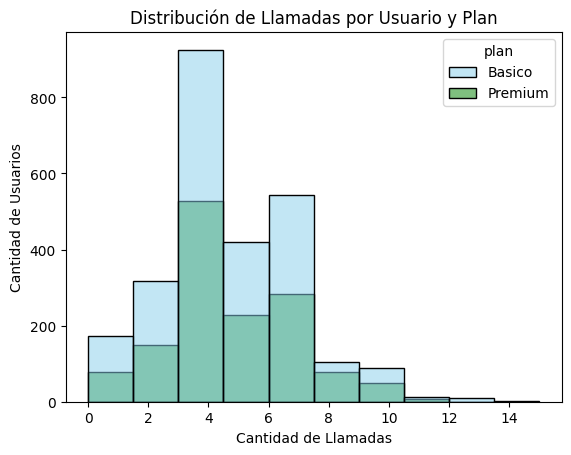

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=10
)

plt.title('Distribución de Llamadas por Usuario y Plan')
plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Cantidad de Usuarios')
plt.show()


💡Insights:
- Distribución: Observaciones clave del gráfico
1. Concentración de la actividad (Moda y distribución):

- El mayor volumen de usuarios se concentra en el rango de 3 a 4.5 llamadas, con un pico máximo (mode) que supera los 900 usuarios en total.

- Existe un segundo pico secundario (bimodalidad leve) en el rango de 6 a 7.5 llamadas, que supera los 500 usuarios.

2. Comparativa por Plan (Básico vs. Premium):

- Plan Básico (azul claro): Mantiene la mayor participación en volumen en todos los rangos de llamadas.

- Plan Premium (verde): Sigue exactamente el mismo patrón de distribución que el plan Básico, representando aproximadamente el 40–50% de la barra en cada intervalo.

3. Consumo marginal y valores extremos:

- La inmensa mayoría de la población realiza entre 0 y 10 llamadas.

- A partir de las 10.5 a 12 llamadas, la frecuencia cae casi a cero, mostrando que un número mínimo de usuarios supera este umbral.

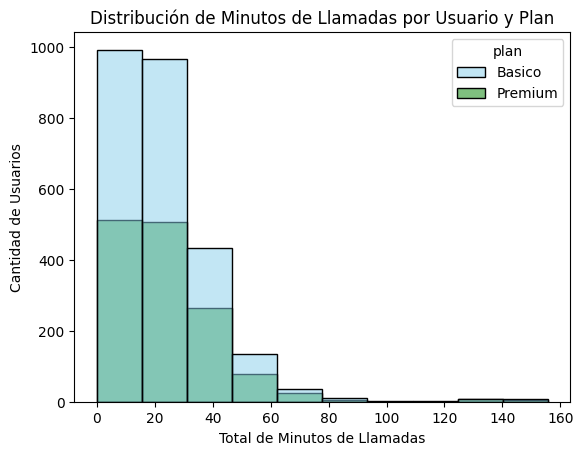

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=10
)

plt.title('Distribución de Minutos de Llamadas por Usuario y Plan')
plt.xlabel('Total de Minutos de Llamadas')
plt.ylabel('Cantidad de Usuarios')
plt.show()


💡Insights:

- **Concentración en Minutos Hablados:** La inmensa mayoría de los clientes registra un consumo total de voz muy reducido, concentrándose principalmente entre los 0 y 30 minutos de llamadas en todo el periodo.
- **Subutilización Significativa de la Cuota de Voz:** Teniendo en cuenta que el plan Básico incluye 100 minutos y el plan Premium incluye 600 minutos, prácticamente ningún usuario agota la cuota asignada. Incluso en el plan Básico, menos del 5% de los usuarios supera los 60 minutos consumidos.
- **Homogeneidad entre Planes:** Los clientes del plan Premium no muestran una conducta de consumo de voz diferenciada respecto a los del plan Básico. Esto indica que la decisión de contratar Premium no responde a una necesidad de mayor volumen de minutos de llamadas.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

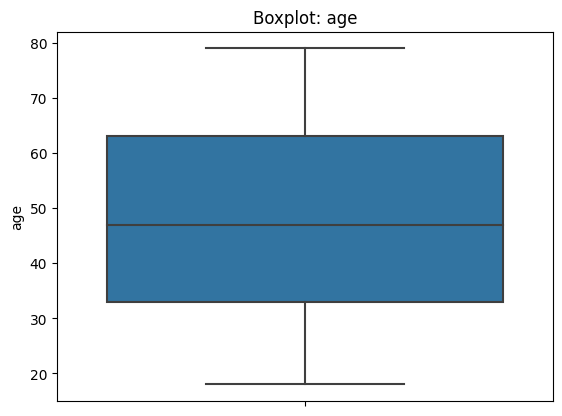

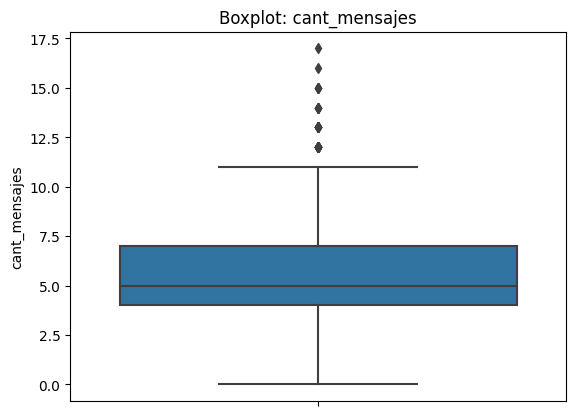

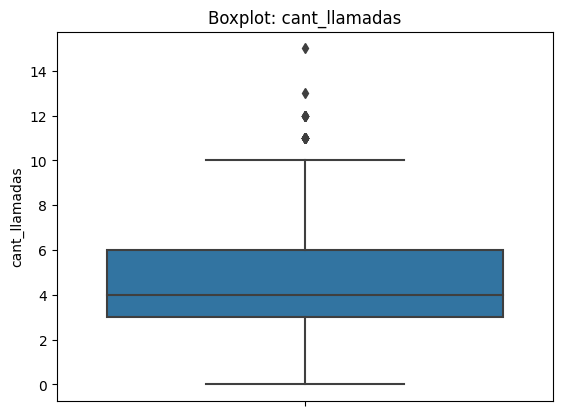

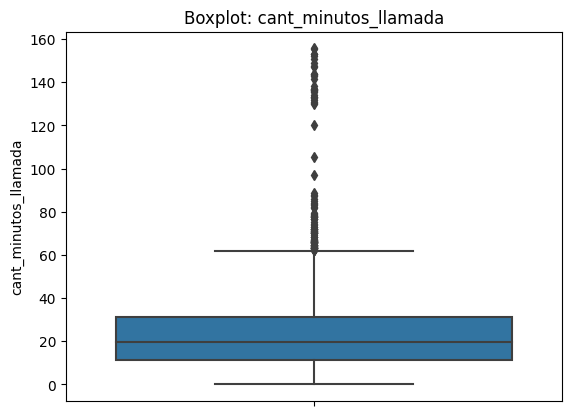

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, y=col)
    plt.title(f'Boxplot: {col}')
    plt.ylabel(col)
    plt.show()

💡Insights:
- Age: No presenta outliers. Luego de imputar el valor sentinel (-999) con la mediana, todas las edades se ubican entre los 18 y 79 años, manteniéndose dentro de los límites del método IQR (-12 y 108 años).
  
- cant_mensajes: Presenta outliers hacia la derecha. Aunque la mayoría de los usuarios envía entre 2.5 y 10 mensajes, existe una minoría con valores atípicos de consumo alto que superan los 12.5 mensajes.

  
- cant_llamadas: Presenta un número muy reducido de outliers. La gran mayoría de los usuarios realiza entre 0 y 10 llamadas, mientras que solo un porcentaje marginal supera las 10.5 a 12 llamadas.


- cant_minutos_llamada: Presenta una presencia clara de outliers de alto consumo. La concentración principal está entre 0 y 30 minutos, pero existen valores atípicos aislados que alcanzan hasta los 160 minutos hablados.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = [
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr

    print(f'{col}:')
    print(f'Q1 = {q1:.2f}')
    print(f'Q3 = {q3:.2f}')
    print(f'IQR = {iqr:.2f}')
    print(f'Límite superior = {limite_superior:.2f}')
    print(f'Máximo = {user_profile[col].max():.2f}')
    print()



cant_mensajes:
Q1 = 4.00
Q3 = 7.00
IQR = 3.00
Límite superior = 11.50
Máximo = 17.00

cant_llamadas:
Q1 = 3.00
Q3 = 6.00
IQR = 3.00
Límite superior = 10.50
Máximo = 15.00

cant_minutos_llamada:
Q1 = 11.12
Q3 = 31.41
IQR = 20.30
Límite superior = 61.86
Máximo = 155.69



In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights:
- cant_mensajes: mantener o no outliers, porqué?

- **cant_mensajes:** Presenta valores atípicos. Con un IQR de 3.00 ($Q_1=4.00$, $Q_3=7.00$), el límite superior estadístico se fija en 11.50 mensajes. Los usuarios que registran entre 12 y 17 mensajes superan este umbral.

- cant_llamadas: mantener o no outliers, porqué?

- **cant_llamadas:** Presenta outliers marginales. La distribución se concentra principalmente entre 0 y 10 llamadas, con solo un número reducido de casos que exceden el límite superior del método IQR.

- cant_minutos_llamada: mantener o no outliers, porqué?

- **cant_minutos_llamada:** Presenta un sesgo positivo pronunciado con presencia clara de outliers de alto consumo. Mientras que el $Q_3$ y el límite superior IQR ubican el comportamiento habitual por debajo de los 60–75 minutos, se registran picos atípicos que alcanzan hasta los 160 minutos hablados.


In [ ]:
# Crear columna grupo_uso


In [ ]:
# verificar cambios
user_profile.head()

In [ ]:
# Crear columna grupo_edad


In [ ]:
# verificar cambios
user_profile.head()

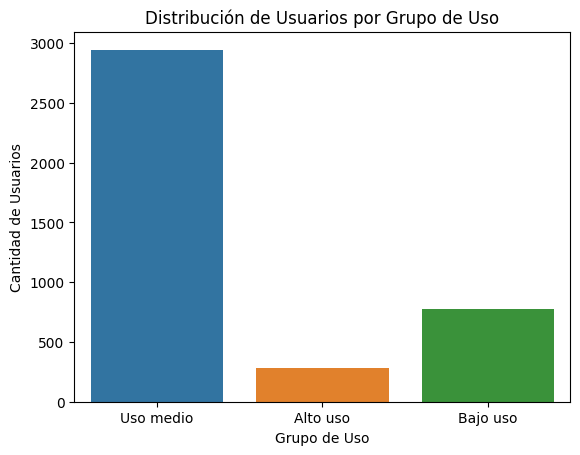

In [ ]:
# Visualización de los segmentos por uso
import numpy as np

# Crear las condiciones de los grupos de uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]

# Nombres de los grupos
grupos = ['Bajo uso', 'Uso medio']

# Crear la columna grupo_uso
user_profile['grupo_uso'] = np.select(
    condiciones,
    grupos,
    default='Alto uso'
)

# Visualización de los segmentos por uso
sns.countplot(
    data=user_profile,
    x='grupo_uso'
)

plt.title('Distribución de Usuarios por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Usuarios')
plt.show()

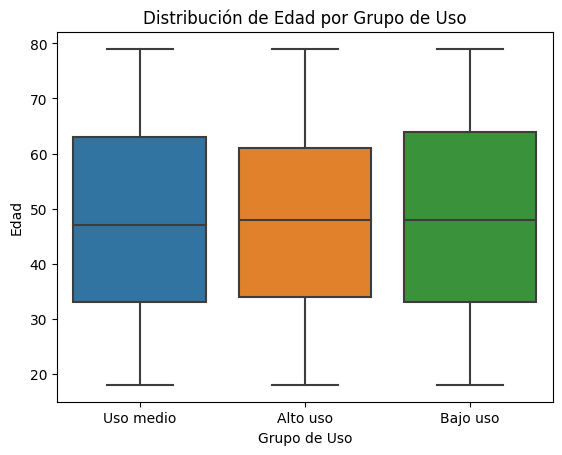

In [ ]:
# Visualización de los segmentos por edad

sns.boxplot(
    data=user_profile,
    x='grupo_uso',
    y='age'
)

plt.title('Distribución de Edad por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Edad')
plt.show()

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Diagnóstico sobre la calidad original de los datos
Durante la fase de exploración inicial se identificaron y corrigieron diversas inconsistencias críticas:

- **Valores Sentinels:**

a. La variable age (4,000 registros) presentaba el valor -999 como código de error/desconocido.

b. La variable city contenía el carácter ? representando ubicaciones no registradas (11.7% / 469 filas).

- **Fechas fuera de rango:** En la columna reg_date, se detectaron 40 registros etiquetados con el año 2026 (1% del total), representando fechas futuras inconsistentes con el período histórico evaluado (hasta 2024).

- **Valores Nulos Estructurados (MAR):** Las columnas duration (55.2% nulos) y length (44.7% nulos) en el dataset de uso presentaron valores faltantes esperados (Missing At Random), derivados directamente de la naturaleza del registro (call frente a text).


🔍 **Segmentos por Edad**
A través del análisis bivariado y la categorización por nivel de uso (Uso medio, Bajo uso, Alto uso), se identificaron las siguientes dinámicas:

- **Uso medio:** Representa el grupo volumétrico principal de la cartera. Se distribuya de manera uniforme entre adultos jóvenes y de mediana edad (18 a 60 años).

- **Segmento Senior (70–80 años):** Muestra una penetración atípicamente alta en la contratación del plan Premium (~70%–80% de este rango de edad), aunque su volumen real de minutos y mensajes consumidos no difiere sustancialmente del promedio general.

- **Comportamiento Homogéneo:** No existe una diferencia drástica en el volumen consumido de llamadas/mensajes entre los usuarios del plan Básico y Premium, lo que indica que la elección del plan Premium no está motivada únicamente por una necesidad intensiva de consumo.


📊 **Segmentos por Nivel de Uso**
- **Adultos Mayores / Senior (Plan Premium):** Es el segmento con mayor Average Revenue Per User (ARPU), ya que pagan la cuota mensual del plan Premium ($25 USD) independientemente de su volumen de consumo.

- **Usuarios de Uso Medio (18–60 años):** Constituyen la base más estable y de mayor volumen de la compañía, representando la principal fuente de ingresos recurrentes sostenibles.



➡️ **Esto sugiere que...** existe un desalineamiento entre la contratación de planes y las necesidades reales de consumo. La elección del plan Premium en el segmento Senior responde más a factores de venta, empaquetado o percepción de servicio que a un consumo intensivo de voz o datos. Asimismo, la alta concentración de usuarios de uso medio en planes con exceso de minutos muestra que la propuesta de valor actual de ConnectaTel está sobredimensionada en servicios tradicionales (minutos/mensajes) y subaprovechada en lo que respecta a la demanda real de datos móviles.


💡 **Recomendaciones**
1. **Rediseño del Plan Básico / Entrada:** Ajustar la cuota de minutos y mensajes hacia abajo (por ejemplo, de 100 a 50 min/mensajes) e incrementar la cuota de navegación por datos (GB), alineándolo con el consumo real del usuario promedio.

2. **Estrategia de Fidelización Senior:** Crear un plan ajustado ("Plan Dorado" o "Senior Comfort") que mantenga el ARPU mediante beneficios de valor agregado (soporte prioritario, servicios de salud o datos ilimitados para apps esenciales) en lugar de grandes paquetes de minutos/SMS tradicionales que no utilizan.

3. **Optimización de Costos Marginales:** Monitorear a los usuarios atípicos de muy alto consumo de minutos (>100 min) para evaluar posibles usos comerciales no autorizados o proponerles paquetes corporativos/dedicados.

4. **Crear ofertas para usuarios de alto consumo:** Los clientes identificados como usuarios de alto consumo pueden ser candidatos para paquetes adicionales o planes especializados. Antes de realizar cambios comerciales, sería recomendable analizar la rentabilidad individual y el comportamiento histórico de estos clientes.